<a href="https://colab.research.google.com/github/24sahil25-source/BA305-BoardGameGeek-Fall2026/blob/main/notebooks/04_predictive_first_pass_sahil.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predictive first pass: average rating from design attributes

Predicts a game's `average` user rating from attributes known before release, using `data/bgg_clean.csv`. Four models on one 70/30 split and one metric: a training-mean baseline, linear regression, a regression tree, and k-nearest-neighbours regression. Each model's fit is diagnosed with train-versus-test curves, two hyperparameters are tuned per model with 5-fold cross-validation on the training rows, and the test rows are scored once at the end.

Inputs: year of publication, player-count range, play-time range, minimum age, the number of mechanics and categories, and 0/1 columns for the most common mechanics and categories. Post-release columns (`rank`, `bayes_average`, `users_rated`, `owned`, `trading`, `wanting`, `wishing`) are never used as inputs; the column audit in the cleaning notebook explains why.

In [1]:
# --- Sahil Dalal: predictive first pass, baseline, linear regression, regression tree, k-NN regression ---
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14. Every code and markdown cell in this notebook was generated with Claude Code and reviewed, run and edited by Sahil Dalal.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## 1. Load and define the rows

In [2]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Load the cleaned catalogue straight from the repository; the same line works in Colab and locally.
BASE = "https://raw.githubusercontent.com/24sahil25-source/BA305-BoardGameGeek-Fall2026/main/data/"
games = pd.read_csv(BASE + "bgg_clean.csv")
print(games.shape)

(21631, 24)


In [3]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Rows: games with every input attribute known. Rows with a missing input are dropped rather than imputed in this first pass; the count is reported so the choice can be revisited.
numeric_cols = ["yearpublished", "minplayers", "maxplayers", "minplaytime", "maxplaytime", "minage", "n_mechanics", "n_categories"]
needed = numeric_cols + ["boardgamemechanic", "boardgamecategory", "average"]
data = games.dropna(subset=needed).reset_index(drop=True)
print("games used:", len(data), "of", len(games), "| dropped for a missing input:", len(games) - len(data))
print("target: average rating, mean", round(data["average"].mean(), 3), "| standard deviation", round(data["average"].std(), 3))

games used: 17982 of 21631 | dropped for a missing input: 3649
target: average rating, mean 6.467 | standard deviation 0.896


In [4]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Figures are saved into the repository's figures folder when the notebook runs inside the repository, otherwise next to the notebook.
FIG_DIR = "../figures" if os.path.isdir("../figures") else "."

def save(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches="tight")

## 2. Split first, then build the inputs

The split happens before anything is fitted. The list of "most common" mechanics and categories is taken from the training rows only, and the same list is applied to the test rows, so nothing about the test rows influences how the inputs are built.

In [5]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# 70/30 split of the rows, fixed random state so the split is reproducible. No stratification: the target is continuous.
train_df, test_df = train_test_split(data, test_size=0.3, random_state=1)
y_train = train_df["average"]
y_test = test_df["average"]
print("training rows:", len(train_df), "| test rows:", len(test_df))

training rows: 12587 | test rows: 5395


In [6]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# The most common mechanics and categories, counted on the training rows only.
N_MECH, N_CAT = 20, 15
top_mech = train_df["boardgamemechanic"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(N_MECH).index
top_cat = train_df["boardgamecategory"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(N_CAT).index
print("mechanics kept:", list(top_mech))
print("categories kept:", list(top_cat))

mechanics kept: ['Dice Rolling', 'Hand Management', 'Set Collection', 'Variable Player Powers', 'Hexagon Grid', 'Simulation', 'Tile Placement', 'Card Drafting', 'Modular Board', 'Area Majority / Influence', 'Grid Movement', 'Cooperative Game', 'Roll / Spin and Move', 'Simultaneous Action Selection', 'Action Points', 'Area Movement', 'Take That', 'Auction/Bidding', 'Team-Based Game', 'Solo / Solitaire Game']
categories kept: ['Card Game', 'Wargame', 'Fantasy', 'Dice', 'Party Game', 'Science Fiction', 'Fighting', 'Economic', "Children's Game", 'Abstract Strategy', 'Animals', 'Bluffing', 'Adventure', 'Humor', 'Deduction']


In [7]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Build the input table for any set of rows: log10 of the skewed counts and times (as in the descriptive notebooks), plus 0/1 columns for the kept mechanics and categories.
def build_inputs(frame, numeric, mechanics, categories):
    X = frame[numeric].copy()
    for col in ["minplayers", "maxplayers", "minplaytime", "maxplaytime"]:
        if col in X.columns:
            X[col] = np.log10(X[col])
    mech = frame["boardgamemechanic"].str.get_dummies(sep="|").reindex(columns=mechanics, fill_value=0).add_prefix("mech_")
    cat = frame["boardgamecategory"].str.get_dummies(sep="|").reindex(columns=categories, fill_value=0).add_prefix("cat_")
    return pd.concat([X, mech, cat], axis=1)

X_train = build_inputs(train_df, numeric_cols, top_mech, top_cat)
X_test = build_inputs(test_df, numeric_cols, top_mech, top_cat)
print("inputs:", X_train.shape[1], "columns")
X_train.head(3)

inputs: 43 columns


,yearpublished,minplayers,maxplayers,minplaytime,maxplaytime,minage,n_mechanics,n_categories,mech_Dice Rolling,mech_Hand Management,...,cat_Science Fiction,cat_Fighting,cat_Economic,cat_Children's Game,cat_Abstract Strategy,cat_Animals,cat_Bluffing,cat_Adventure,cat_Humor,cat_Deduction
4245,2004.0,0.30103,0.301030,1.653213,1.653213,13.0,5.0,2.0,1,0,...,0,0,0,0,0,0,0,1,0,0
10132,1996.0,0.00000,0.301030,2.380211,2.380211,12.0,1.0,2.0,0,0,...,0,0,0,0,0,0,0,0,0,0
11423,2002.0,0.30103,0.778151,2.079181,2.079181,12.0,3.0,4.0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [8]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# One function to score a fitted model on the training and test rows with the metrics used throughout: RMSE, MAE and R-squared.
def score(model, X_tr, y_tr, X_te, y_te):
    pred_tr = model.predict(X_tr)
    pred_te = model.predict(X_te)
    return {
        "train RMSE": np.sqrt(mean_squared_error(y_tr, pred_tr)),
        "test RMSE": np.sqrt(mean_squared_error(y_te, pred_te)),
        "test MAE": mean_absolute_error(y_te, pred_te),
        "test R2": r2_score(y_te, pred_te),
    }

folds = KFold(n_splits=5, shuffle=True, random_state=0)
results = {}

## 3. Baseline: predict the training mean for every game

In [9]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# The number every model has to beat: predict the mean training rating for every test game.
naive = np.full(len(y_test), y_train.mean())
results["Baseline (training mean)"] = {
    "train RMSE": np.sqrt(mean_squared_error(y_train, np.full(len(y_train), y_train.mean()))),
    "test RMSE": np.sqrt(mean_squared_error(y_test, naive)),
    "test MAE": mean_absolute_error(y_test, naive),
    "test R2": r2_score(y_test, naive),
}
pd.Series(results["Baseline (training mean)"]).round(3)

train RMSE    0.893
test RMSE     0.903
test MAE      0.709
test R2      -0.000
dtype: float64

Predicting the training mean for every game gives a test RMSE of 0.903 rating points, the number every model has to beat. R-squared is 0 by construction.

## 4. Linear regression

In [10]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Linear regression on the inputs as built (no scaling needed for a linear model); 5-fold cross-validated RMSE on the training rows as the stability check.
lin = LinearRegression().fit(X_train, y_train)
results["Linear regression"] = score(lin, X_train, y_train, X_test, y_test)
lin_cv = -cross_val_score(LinearRegression(), X_train, y_train, scoring="neg_root_mean_squared_error", cv=folds)
results["Linear regression"]["CV RMSE (train, 5-fold)"] = lin_cv.mean()
print("5-fold CV RMSE per fold:", lin_cv.round(3), "| mean", round(lin_cv.mean(), 3), "| std", round(lin_cv.std(), 3))
pd.Series(results["Linear regression"]).round(3)

5-fold CV RMSE per fold: [0.742 0.726 0.713 0.714 0.724] | mean 0.724 | std 0.01


train RMSE                 0.721
test RMSE                  0.729
test MAE                   0.562
test R2                    0.347
CV RMSE (train, 5-fold)    0.724
dtype: float64

Linear regression: test RMSE 0.729, MAE 0.562, R-squared 0.347. The five cross-validation folds range from 0.713 to 0.742, and training and test RMSE are within 0.01 of each other.

## 5. Regression tree

max_depth,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
train RMSE,0.824,0.774,0.74,0.710,0.689,0.671,0.653,0.631,0.609,0.583,0.554,0.523,0.491,0.458,0.423,0.387,0.352,0.317,0.286,0.259
test RMSE,0.830,0.779,0.75,0.725,0.710,0.702,0.697,0.702,0.712,0.724,0.736,0.756,0.770,0.793,0.817,0.834,0.844,0.865,0.874,0.879


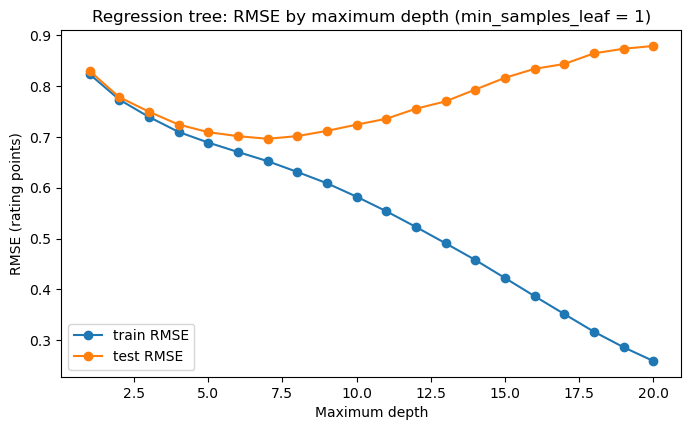

In [11]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Depth sweep: training and test RMSE for trees of increasing depth. A gap that widens as depth grows is the overfitting evidence.
sweep = []
for depth in range(1, 21):
    tree = DecisionTreeRegressor(max_depth=depth, random_state=0).fit(X_train, y_train)
    s = score(tree, X_train, y_train, X_test, y_test)
    sweep.append({"max_depth": depth, "train RMSE": s["train RMSE"], "test RMSE": s["test RMSE"]})
tree_sweep = pd.DataFrame(sweep)
ax = tree_sweep.plot(x="max_depth", y=["train RMSE", "test RMSE"], marker="o", figsize=(8, 4.5))
ax.set_title("Regression tree: RMSE by maximum depth (min_samples_leaf = 1)")
ax.set_xlabel("Maximum depth")
ax.set_ylabel("RMSE (rating points)")
save("04_tree_depth_sweep.png")
tree_sweep.round(3).set_index("max_depth").T

Test RMSE falls from 0.830 at depth 1 to 0.697 at depth 7, then rises to 0.879 at depth 20 while training RMSE keeps falling to 0.259: beyond depth 7 the tree fits the training rows at the expense of new ones.

In [12]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Tune two hyperparameters, maximum depth and minimum rows per leaf, with 5-fold cross-validation on the training rows only.
param_grid = {"max_depth": [3, 4, 5, 6, 8, 10, 12, 15], "min_samples_leaf": [5, 20, 50, 100, 200]}
tree_grid = GridSearchCV(DecisionTreeRegressor(random_state=0), param_grid, cv=folds, scoring="neg_root_mean_squared_error")
tree_grid.fit(X_train, y_train)
tree_best = tree_grid.best_estimator_
print("best settings:", tree_grid.best_params_, "| CV RMSE:", round(-tree_grid.best_score_, 3))
cv_table = pd.DataFrame(tree_grid.cv_results_).pivot(index="param_max_depth", columns="param_min_samples_leaf", values="mean_test_score")
(-cv_table).round(3)

best settings: {'max_depth': 10, 'min_samples_leaf': 50} | CV RMSE: 0.68


param_min_samples_leaf,5,20,50,100,200
param_max_depth,,,,,
3,0.742,0.742,0.742,0.742,0.743
4,0.717,0.717,0.717,0.718,0.719
5,0.701,0.701,0.701,0.703,0.706
6,0.692,0.690,0.690,0.692,0.699
8,0.690,0.685,0.681,0.685,0.697
10,0.699,0.686,0.680,0.684,0.697
12,0.716,0.688,0.681,0.684,0.697
15,0.735,0.690,0.681,0.684,0.697


In [13]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Score the tuned tree once on the test rows.
results["Regression tree (tuned)"] = score(tree_best, X_train, y_train, X_test, y_test)
results["Regression tree (tuned)"]["CV RMSE (train, 5-fold)"] = -tree_grid.best_score_
pd.Series(results["Regression tree (tuned)"]).round(3)

train RMSE                 0.648
test RMSE                  0.684
test MAE                   0.522
test R2                    0.425
CV RMSE (train, 5-fold)    0.680
dtype: float64

The best cross-validated setting is depth 10 with at least 50 rows per leaf (CV RMSE 0.680); the leaf-size limit is what allows the deeper tree without the overfitting seen in the sweep. Scored once on the test rows: RMSE 0.684, MAE 0.522, R-squared 0.425, with training RMSE 0.648.

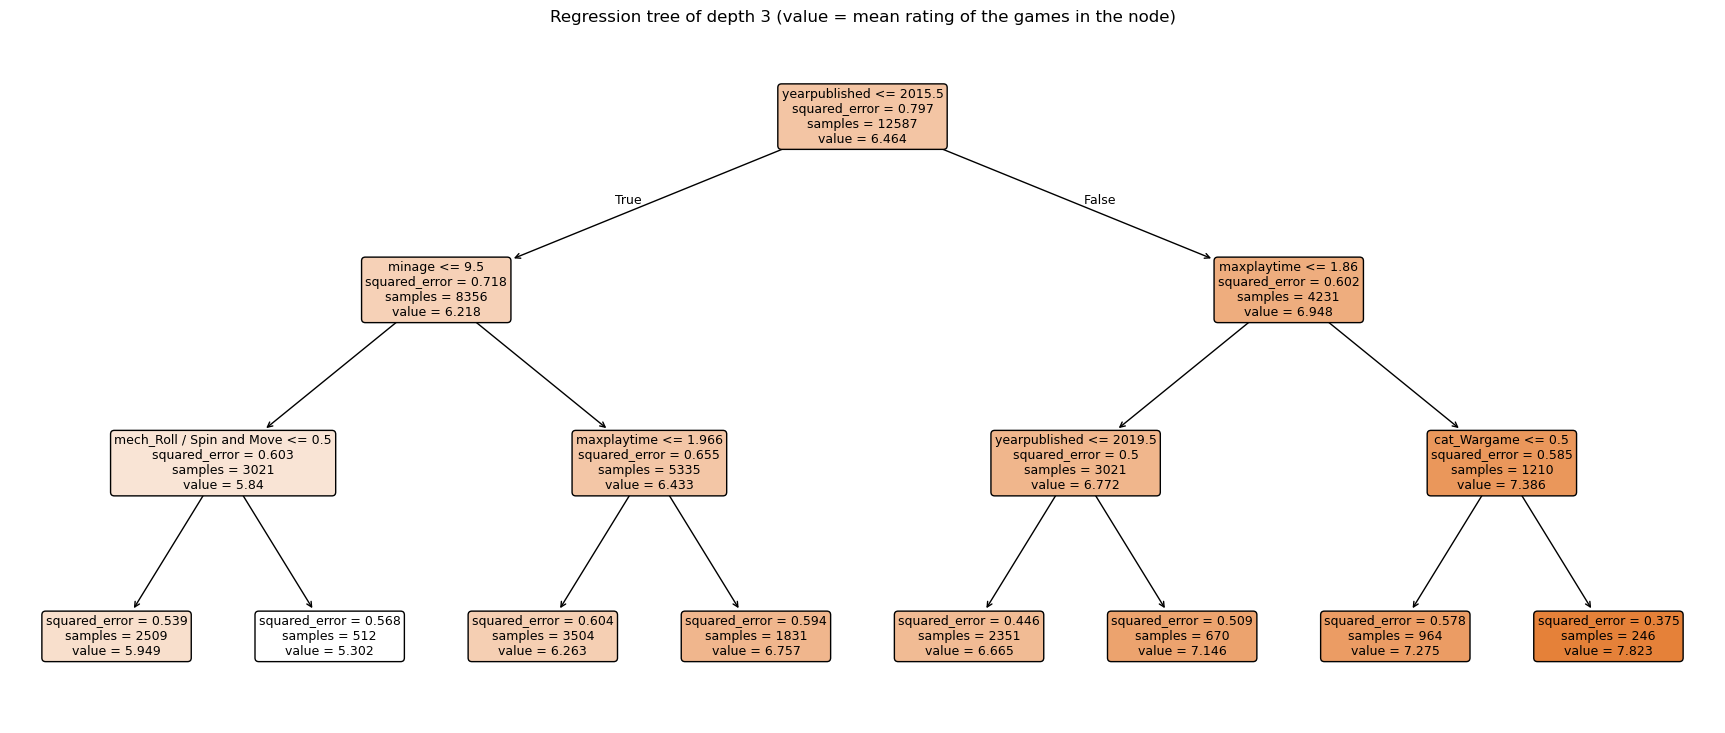

In [14]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# A depth-3 tree drawn in full, to show what the splits look like.
small_tree = DecisionTreeRegressor(max_depth=3, random_state=0).fit(X_train, y_train)
plt.figure(figsize=(22, 9))
plot_tree(small_tree, feature_names=list(X_train.columns), filled=True, fontsize=9, rounded=True)
plt.title("Regression tree of depth 3 (value = mean rating of the games in the node)")
save("04_tree_depth3.png")

yearpublished                0.428
maxplaytime                  0.170
minage                       0.155
n_mechanics                  0.095
mech_Roll / Spin and Move    0.068
maxplayers                   0.035
cat_Wargame                  0.017
minplaytime                  0.010
mech_Dice Rolling            0.004
n_categories                 0.003
cat_Party Game               0.003
cat_Card Game                0.003
cat_Abstract Strategy        0.003
minplayers                   0.002
cat_Dice                     0.001
dtype: float64

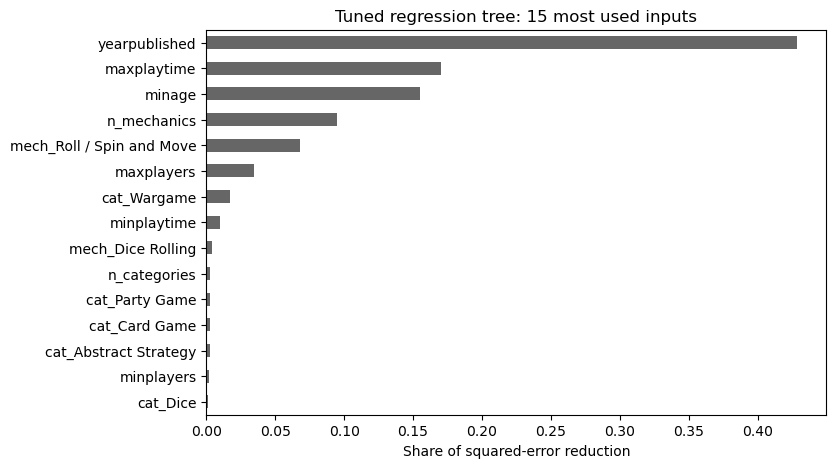

In [15]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Which inputs the tuned tree splits on most: share of the squared-error reduction attributed to each input.
importance = pd.Series(tree_best.feature_importances_, index=X_train.columns).sort_values(ascending=False)
ax = importance.head(15).plot(kind="barh", color="0.4", figsize=(8, 5))
ax.invert_yaxis()
ax.set_title("Tuned regression tree: 15 most used inputs")
ax.set_xlabel("Share of squared-error reduction")
save("04_tree_feature_importance.png")
importance.head(15).round(3)

Year of publication accounts for 0.43 of the tuned tree's squared-error reduction, maximum play time 0.17, minimum age 0.16, and the number of mechanics 0.10. No single mechanic or category exceeds 0.07.

## 6. k-nearest-neighbours regression

k,1,2,3,5,7,10,15,20,30,40,50,75,100
train RMSE,0.056,0.474,0.555,0.620,0.648,0.667,0.685,0.696,0.709,0.717,0.722,0.732,0.738
test RMSE,0.962,0.847,0.807,0.775,0.766,0.754,0.748,0.744,0.745,0.748,0.749,0.753,0.758


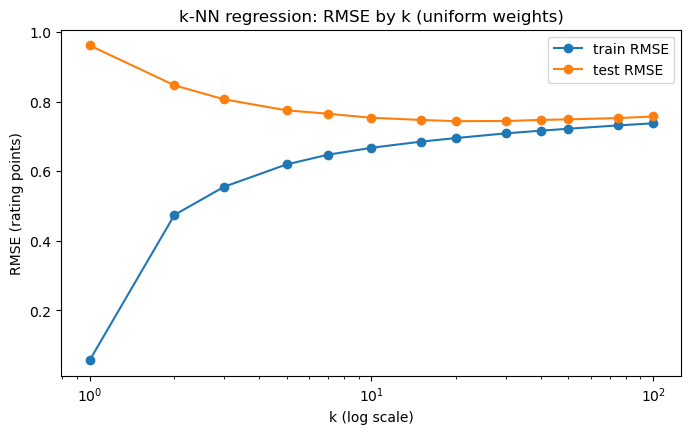

In [16]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Same algorithm as the k-NN classifier from the course lab, with one change: the prediction is the average rating of the k nearest games instead of a majority vote. Inputs are standardized inside a pipeline so the scaler is fit on the training rows only.
sweep = []
for k in [1, 2, 3, 5, 7, 10, 15, 20, 30, 40, 50, 75, 100]:
    knn = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k)).fit(X_train, y_train)
    s = score(knn, X_train, y_train, X_test, y_test)
    sweep.append({"k": k, "train RMSE": s["train RMSE"], "test RMSE": s["test RMSE"]})
knn_sweep = pd.DataFrame(sweep)
ax = knn_sweep.plot(x="k", y=["train RMSE", "test RMSE"], marker="o", figsize=(8, 4.5))
ax.set_xscale("log")
ax.set_title("k-NN regression: RMSE by k (uniform weights)")
ax.set_xlabel("k (log scale)")
ax.set_ylabel("RMSE (rating points)")
save("04_knn_k_sweep.png")
knn_sweep.round(3).set_index("k").T

With equal weights, test RMSE falls from 0.962 at k = 1 to 0.744 at k = 20 and drifts up slowly after that, while training RMSE rises from 0.056 toward the test curve: small k memorizes the training games, large k smooths over them.

In [17]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Tune two hyperparameters, k and the weighting of neighbours (equal, or closer neighbours count more), with 5-fold cross-validation on the training rows only.
knn_pipe = make_pipeline(StandardScaler(), KNeighborsRegressor())
knn_param_grid = {"kneighborsregressor__n_neighbors": [5, 10, 15, 20, 30, 40, 50, 75], "kneighborsregressor__weights": ["uniform", "distance"]}
knn_grid = GridSearchCV(knn_pipe, knn_param_grid, cv=folds, scoring="neg_root_mean_squared_error")
knn_grid.fit(X_train, y_train)
knn_best = knn_grid.best_estimator_
print("best settings:", knn_grid.best_params_, "| CV RMSE:", round(-knn_grid.best_score_, 3))
cv_table = pd.DataFrame(knn_grid.cv_results_).pivot(index="param_kneighborsregressor__n_neighbors", columns="param_kneighborsregressor__weights", values="mean_test_score")
(-cv_table).round(3)

best settings: {'kneighborsregressor__n_neighbors': 30, 'kneighborsregressor__weights': 'distance'} | CV RMSE: 0.728


param_kneighborsregressor__weights,distance,uniform
param_kneighborsregressor__n_neighbors,,
5,0.762,0.765
10,0.738,0.744
15,0.731,0.738
20,0.729,0.736
30,0.728,0.737
40,0.729,0.738
50,0.731,0.741
75,0.735,0.745


In [18]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Score the tuned k-NN once on the test rows.
results["k-NN regression (tuned)"] = score(knn_best, X_train, y_train, X_test, y_test)
results["k-NN regression (tuned)"]["CV RMSE (train, 5-fold)"] = -knn_grid.best_score_
pd.Series(results["k-NN regression (tuned)"]).round(3)

train RMSE                 0.040
test RMSE                  0.736
test MAE                   0.561
test R2                    0.336
CV RMSE (train, 5-fold)    0.728
dtype: float64

The best cross-validated setting is k = 30 with distance weighting (CV RMSE 0.728); test RMSE 0.736, MAE 0.561, R-squared 0.336. The training RMSE of 0.040 under distance weighting is not an overfitting signal: each training game is its own nearest neighbour at distance zero and so predicts itself. The equal-weight sweep above is the fit diagnostic for k-NN.

## 7. Comparison on the same split and the same metric

In [19]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# All four on one table: training RMSE, test RMSE, test MAE, test R-squared, and the cross-validated RMSE where it was computed.
comparison = pd.DataFrame(results).T[["train RMSE", "test RMSE", "test MAE", "test R2", "CV RMSE (train, 5-fold)"]]
comparison.round(3)

,train RMSE,test RMSE,test MAE,test R2,"CV RMSE (train, 5-fold)"
Baseline (training mean),0.893,0.903,0.709,-0.000,NaN
Linear regression,0.721,0.729,0.562,0.347,0.724
Regression tree (tuned),0.648,0.684,0.522,0.425,0.680
k-NN regression (tuned),0.040,0.736,0.561,0.336,0.728


On the same 5,395 test games: tree 0.684, linear 0.729, k-NN 0.736, baseline 0.903 RMSE. Test R-squared: tree 0.425, linear 0.347, k-NN 0.336.

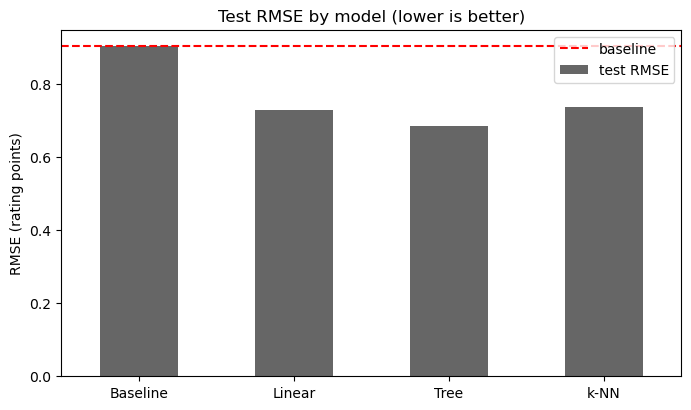

In [20]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Test RMSE per model, with the baseline as the reference line.
ax = comparison["test RMSE"].plot(kind="bar", color="0.4", figsize=(8, 4.5), rot=0)
ax.axhline(comparison.loc["Baseline (training mean)", "test RMSE"], color="red", linestyle="--", label="baseline")
ax.set_title("Test RMSE by model (lower is better)")
ax.set_ylabel("RMSE (rating points)")
ax.set_xticklabels(["Baseline", "Linear", "Tree", "k-NN"])
ax.legend()
save("04_model_comparison.png")

lowest test RMSE: Regression tree (tuned)


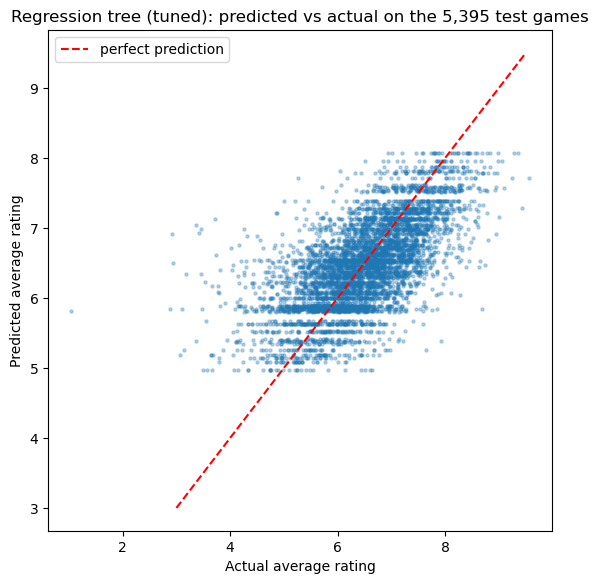

In [21]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Predicted against actual rating on the test rows for the model with the lowest test RMSE.
best_name = comparison["test RMSE"].drop("Baseline (training mean)").idxmin()
best_model = {"Linear regression": lin, "Regression tree (tuned)": tree_best, "k-NN regression (tuned)": knn_best}[best_name]
pred = best_model.predict(X_test)
plt.figure(figsize=(6.5, 6.5))
plt.scatter(y_test, pred, s=5, alpha=0.3)
plt.plot([3, 9.5], [3, 9.5], color="red", linestyle="--", label="perfect prediction")
plt.xlabel("Actual average rating")
plt.ylabel("Predicted average rating")
plt.title(f"{best_name}: predicted vs actual on the {len(y_test):,} test games")
plt.legend()
save("04_predicted_vs_actual.png")
print("lowest test RMSE:", best_name)

## 8. Two checks on the row and input choices

Both re-run the tuned settings from above on a different definition of the rows or inputs, with a fresh split of the same kind, to show how much the headline numbers depend on those choices.

In [22]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Re-run baseline, linear, tuned tree and tuned k-NN on a given set of rows and numeric inputs; returns the comparison table.
def rerun(frame, numeric):
    tr, te = train_test_split(frame, test_size=0.3, random_state=1)
    tm = tr["boardgamemechanic"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(N_MECH).index
    tc = tr["boardgamecategory"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(N_CAT).index
    Xtr, Xte = build_inputs(tr, numeric, tm, tc), build_inputs(te, numeric, tm, tc)
    ytr, yte = tr["average"], te["average"]
    out = {}
    base = np.full(len(yte), ytr.mean())
    out["Baseline"] = {"test RMSE": np.sqrt(mean_squared_error(yte, base)), "test R2": r2_score(yte, base)}
    models = {
        "Linear": LinearRegression(),
        "Tree": DecisionTreeRegressor(random_state=0, **tree_grid.best_params_),
        "k-NN": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=knn_grid.best_params_["kneighborsregressor__n_neighbors"], weights=knn_grid.best_params_["kneighborsregressor__weights"])),
    }
    for name, m in models.items():
        s = score(m.fit(Xtr, ytr), Xtr, ytr, Xte, yte)
        out[name] = {"test RMSE": s["test RMSE"], "test R2": s["test R2"]}
    return pd.DataFrame(out).T.round(3)

print("rows:", len(data), "| all inputs (the main run above)")
rerun(data, numeric_cols)

rows: 17982 | all inputs (the main run above)


,test RMSE,test R2
Baseline,0.903,-0.000
Linear,0.729,0.347
Tree,0.684,0.425
k-NN,0.736,0.336


In [23]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Check 1: only games with at least 100 ratings, where the average is less noisy. users_rated is used to choose rows here, never as an input.
subset = data[data["users_rated"] >= 100]
print("rows:", len(subset), "| games with at least 100 ratings")
rerun(subset, numeric_cols)

rows: 10980 | games with at least 100 ratings


,test RMSE,test R2
Baseline,0.819,-0.000
Linear,0.668,0.335
Tree,0.615,0.437
k-NN,0.670,0.332


Restricting to the 10,980 games with at least 100 ratings lowers every RMSE, including the baseline (0.903 to 0.819), because the target itself is less noisy. The ordering of the models is unchanged; the tree's R-squared is 0.437.

In [24]:
# [AI-assisted] Claude Code (Claude Fable 5.1), 2026-10-14; reviewed and edited by Sahil Dalal.
# Check 2: all rows, without the year of publication as an input.
print("rows:", len(data), "| inputs without yearpublished")
rerun(data, [c for c in numeric_cols if c != "yearpublished"])

rows: 17982 | inputs without yearpublished


,test RMSE,test R2
Baseline,0.903,-0.000
Linear,0.735,0.337
Tree,0.744,0.321
k-NN,0.752,0.307


Without year of publication, the tree's test RMSE rises from 0.684 to 0.744 and its R-squared falls from 0.425 to 0.321; linear moves from 0.729 to 0.735 and k-NN from 0.736 to 0.752.

## 9. Notes on reading this notebook

- One split (70/30, random state 1) is used for every model, and every number labelled "test" comes from scoring that split once, after tuning on the training rows with 5-fold cross-validation.
- The list of kept mechanics and categories, the scaler inside the k-NN pipeline, and every model are fit on the training rows only.
- RMSE and MAE are in rating points on the 1-to-10 scale; R-squared is the share of the variance in test ratings the model accounts for.
- Figures are saved to `figures/` with the prefix `04_`.